# Hourly order demand forecast

In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error


Importing plotly failed. Interactive plots will not work.


In [2]:
from eats_intel.data import load_all

data = load_all()

print(data.keys())

dict_keys(['customers', 'restaurants', 'drivers', 'orders', 'deliveries', 'payments', 'reviews'])


In [3]:
orders = data['orders'].copy()

orders['order_timestamp'] = pd.to_datetime(
    orders['order_timestamp']
)

hourly_orders = (
    orders
    .set_index('order_timestamp')
    .resample('h')
    .size()
    .reset_index(name='order_count')
)

hourly_orders.head()

,order_timestamp,order_count
0,2026-07-29 00:00:00,3
1,2026-07-29 01:00:00,2
2,2026-07-29 02:00:00,1
3,2026-07-29 03:00:00,2
4,2026-07-29 04:00:00,1


In [ ]:
# Make sure timestamps are datetime
hourly_orders['order_timestamp'] = pd.to_datetime(
    hourly_orders['order_timestamp']
)

# Extract time-based features
hourly_orders['hour'] = hourly_orders['order_timestamp'].dt.hour
hourly_orders['day_of_week'] = hourly_orders['order_timestamp'].dt.dayofweek
hourly_orders['day_name'] = hourly_orders['order_timestamp'].dt.day_name()
hourly_orders['is_weekend'] = (
    hourly_orders['day_of_week'] >= 5
)

hourly_orders['date'] = hourly_orders['order_timestamp'].dt.date
hourly_orders['month'] = hourly_orders['order_timestamp'].dt.month

hourly_orders.head()


/tmp/ipykernel_82151/855932166.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hourly_orders['day_of_week'] = hourly_orders['order_timestamp'].dt.dayofweek


,order_timestamp,order_count,hour,day_of_week,day_name,is_weekend,date,month
0,2026-07-29 00:00:00,3,0,2,Wednesday,False,2026-07-29,7
1,2026-07-29 01:00:00,2,1,2,Wednesday,False,2026-07-29,7
2,2026-07-29 02:00:00,1,2,2,Wednesday,False,2026-07-29,7
3,2026-07-29 03:00:00,2,3,2,Wednesday,False,2026-07-29,7
4,2026-07-29 04:00:00,1,4,2,Wednesday,False,2026-07-29,7


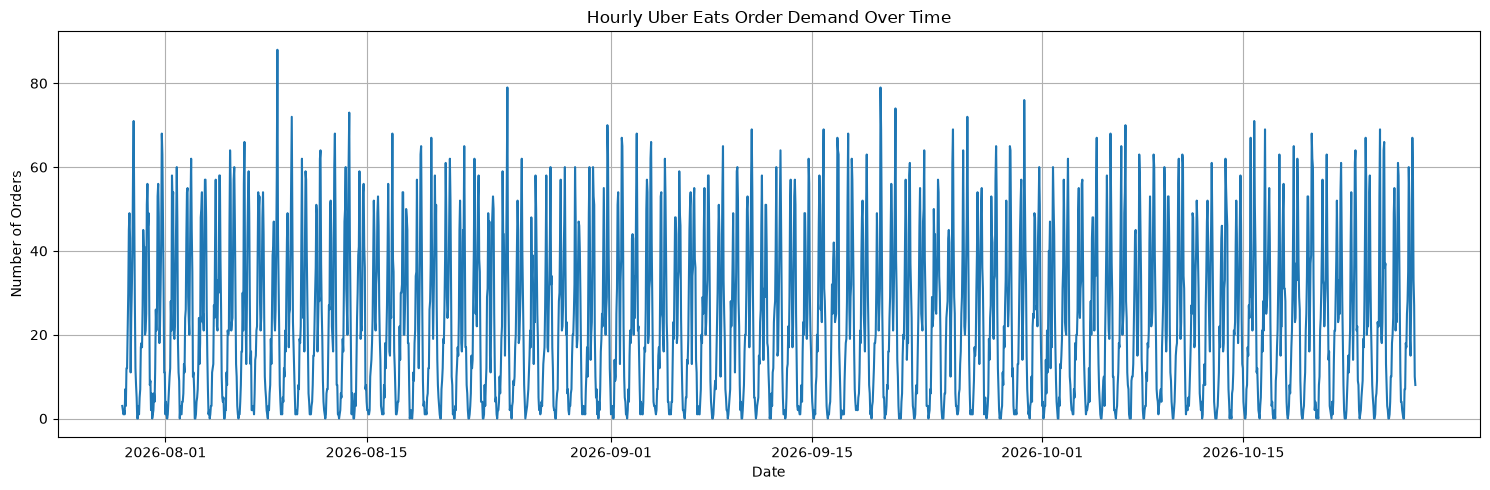

In [5]:

plt.figure(figsize=(15, 5))
plt.plot(
    hourly_orders['order_timestamp'],
    hourly_orders['order_count']
)
plt.title('Hourly Uber Eats Order Demand Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.grid(True)
plt.tight_layout()
plt.show()


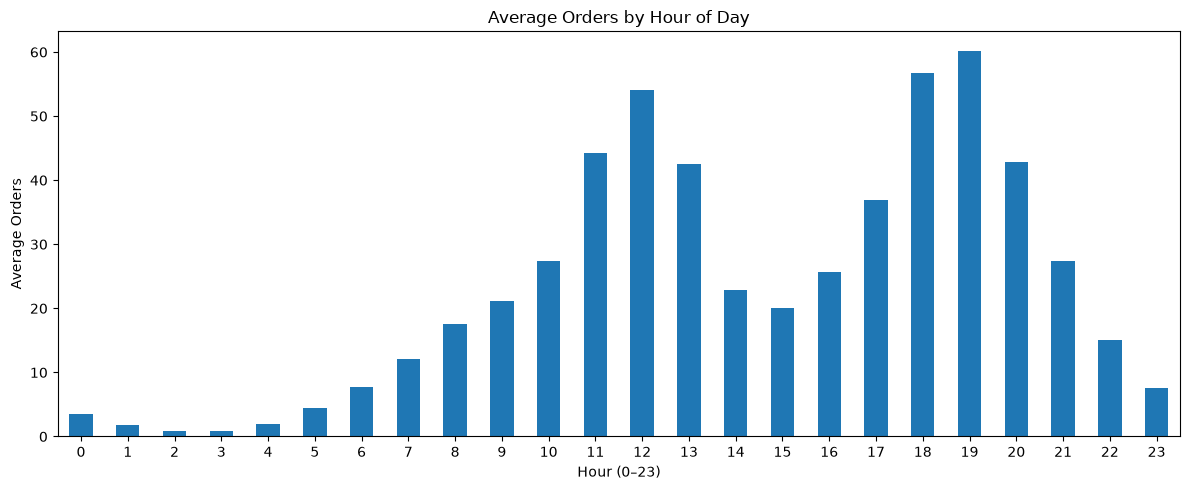

Peak hour: 19
Average orders at peak: 60.22


In [6]:

hourly_pattern = (
    hourly_orders.groupby('hour')['order_count']
    .mean()
)

plt.figure(figsize=(12, 5))
hourly_pattern.plot(kind='bar')
plt.title('Average Orders by Hour of Day')
plt.xlabel('Hour (0–23)')
plt.ylabel('Average Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Peak hour:", hourly_pattern.idxmax())
print("Average orders at peak:", round(hourly_pattern.max(), 2))


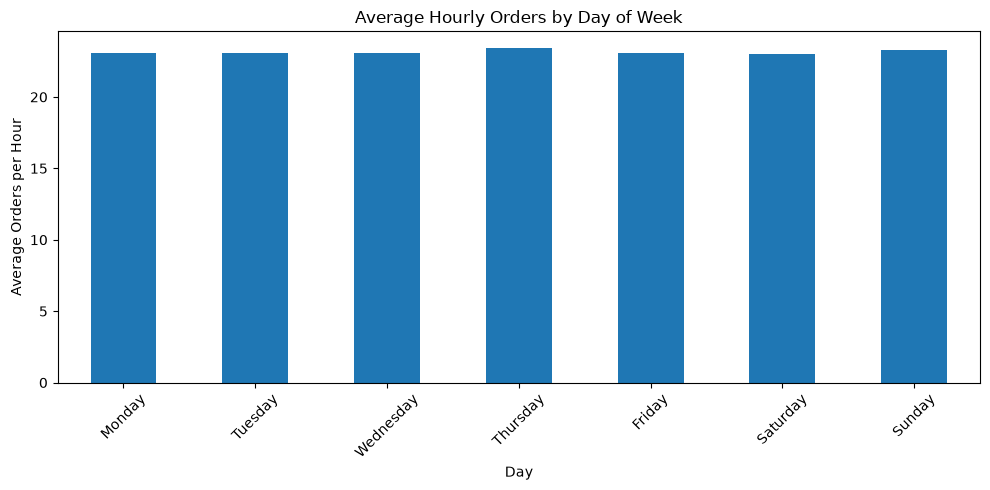

Busiest day: Thursday
Quietest day: Saturday


In [7]:

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_pattern = (
    hourly_orders.groupby('day_name')['order_count']
    .mean()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))
daily_pattern.plot(kind='bar')
plt.title('Average Hourly Orders by Day of Week')
plt.xlabel('Day')
plt.ylabel('Average Orders per Hour')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Busiest day:", daily_pattern.idxmax())
print("Quietest day:", daily_pattern.idxmin())


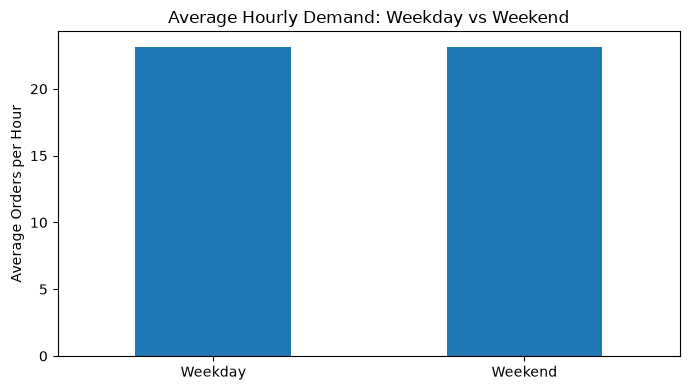

Weekday    23.149740
Weekend    23.144231
Name: order_count, dtype: float64


In [8]:

weekend_pattern = (
    hourly_orders.groupby('is_weekend')['order_count']
    .mean()
)

weekend_pattern.index = ['Weekday', 'Weekend']

weekend_pattern.plot(
    kind='bar',
    figsize=(7, 4),
    title='Average Hourly Demand: Weekday vs Weekend'
)

plt.ylabel('Average Orders per Hour')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(weekend_pattern)


Weekday - Peak hour: 19 - Average orders: 60.22
Weekend - Peak hour: 19 - Average orders: 60.23


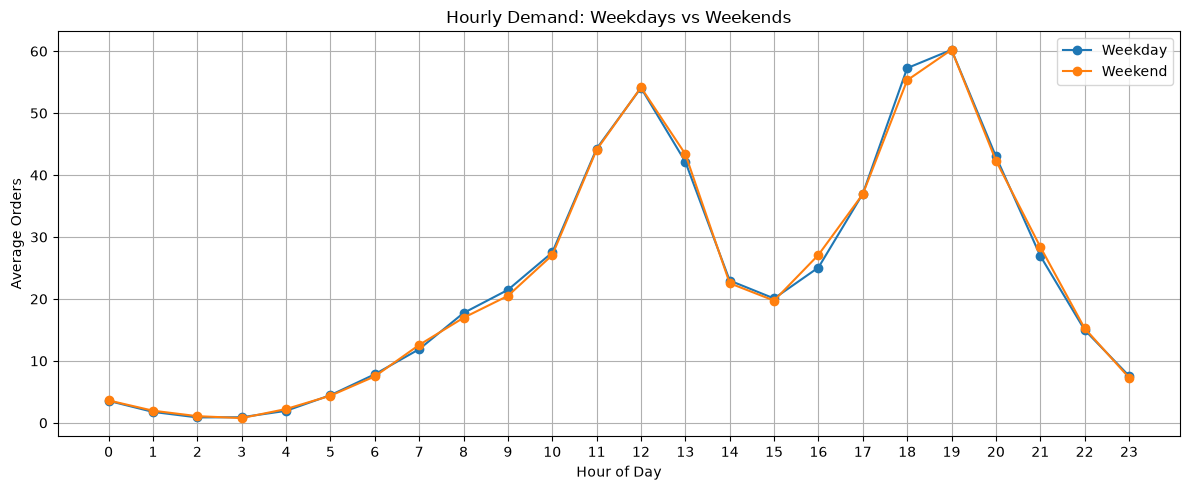

In [9]:

peak_periods = (
    hourly_orders.groupby(['is_weekend', 'hour'])['order_count']
    .mean()
    .reset_index()
)

for is_weekend, group in peak_periods.groupby('is_weekend'):
    label = 'Weekend' if is_weekend else 'Weekday'
    peak_hour = group.loc[group['order_count'].idxmax()]

    print(
        label,
        '- Peak hour:', int(peak_hour['hour']),
        '- Average orders:', round(peak_hour['order_count'], 2)
    )

plt.figure(figsize=(12, 5))

for is_weekend, group in peak_periods.groupby('is_weekend'):
    label = 'Weekend' if is_weekend else 'Weekday'
    plt.plot(
        group['hour'],
        group['order_count'],
        marker='o',
        label=label
    )

plt.title('Hourly Demand: Weekdays vs Weekends')
plt.xlabel('Hour of Day')
plt.ylabel('Average Orders')
plt.xticks(range(24))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


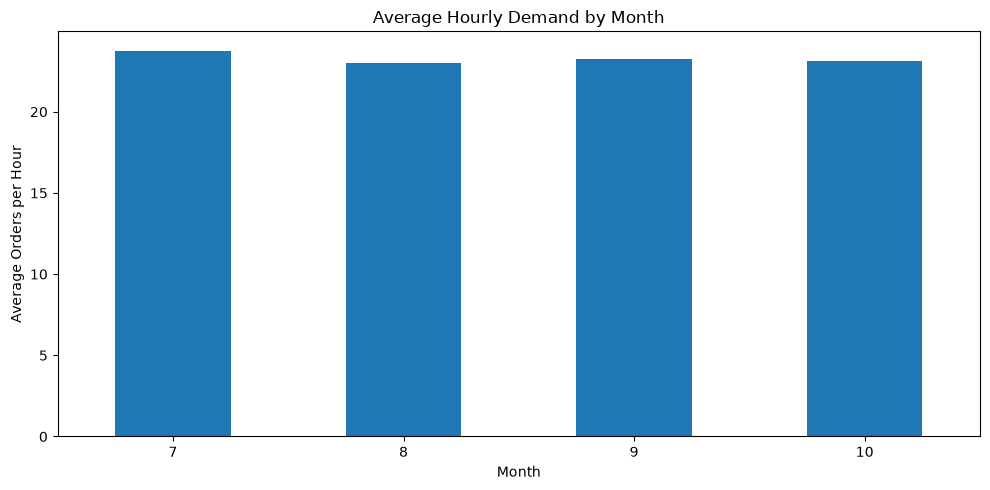

In [10]:

monthly_pattern = (
    hourly_orders.groupby('month')['order_count']
    .mean()
)

plt.figure(figsize=(10, 5))
monthly_pattern.plot(kind='bar')
plt.title('Average Hourly Demand by Month')
plt.xlabel('Month')
plt.ylabel('Average Orders per Hour')
plt.xticks(
    ticks=range(len(monthly_pattern)),
    labels=monthly_pattern.index,
    rotation=0
)
plt.tight_layout()
plt.show()


In [12]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 1.6 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 1.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 2.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.4/250.4 kB 1.7 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


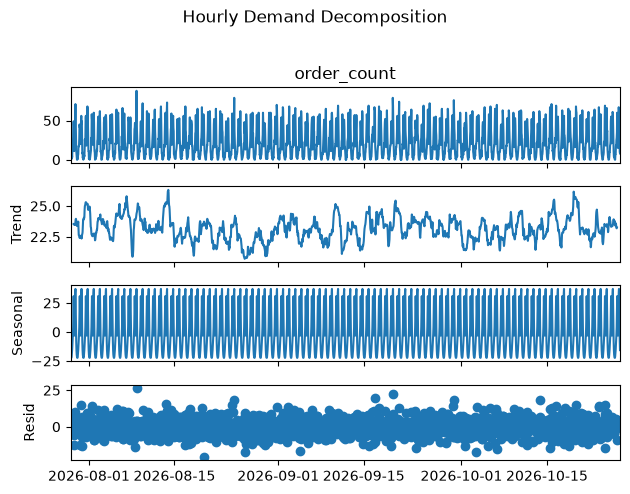

In [13]:

from statsmodels.tsa.seasonal import seasonal_decompose

# Create a continuous hourly time series
ts = (
    hourly_orders
    .set_index('order_timestamp')['order_count']
    .asfreq('h', fill_value=0)
)

# At least two complete daily cycles are needed
if len(ts) >= 48:
    decomposition = seasonal_decompose(
        ts,
        model='additive',
        period=24
    )

    decomposition.plot()
    plt.suptitle(
        'Hourly Demand Decomposition',
        y=1.02
    )
    plt.tight_layout()
    plt.show()
else:
    print("Not enough hourly observations for daily decomposition.")


In [14]:

from statsmodels.tsa.stattools import adfuller

# Remove missing values before testing
adf_result = adfuller(ts.dropna())

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("Critical Values:", adf_result[4])

if adf_result[1] <= 0.05:
    print("The series appears stationary.")
else:
    print("The series may be non-stationary.")


ADF Statistic: -7.283
p-value: 0.0
Critical Values: {'1%': np.float64(-3.433418033468612), '5%': np.float64(-2.862895338734693), '10%': np.float64(-2.567491516545175)}
The series appears stationary.


/tmp/ipykernel_82151/1119165662.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ts.dropna())


In [15]:

# First-order differencing
ts_diff = ts.diff().dropna()

# Test the differenced series
adf_diff = adfuller(ts_diff)

print("ADF Statistic after differencing:", round(adf_diff[0], 4))
print("p-value after differencing:", round(adf_diff[1], 4))

if adf_diff[1] <= 0.05:
    print("The differenced series appears stationary.")
else:
    print("The differenced series may still be non-stationary.")


ADF Statistic after differencing: -29.2372
p-value after differencing: 0.0
The differenced series appears stationary.


/tmp/ipykernel_82151/2376279801.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(ts_diff)


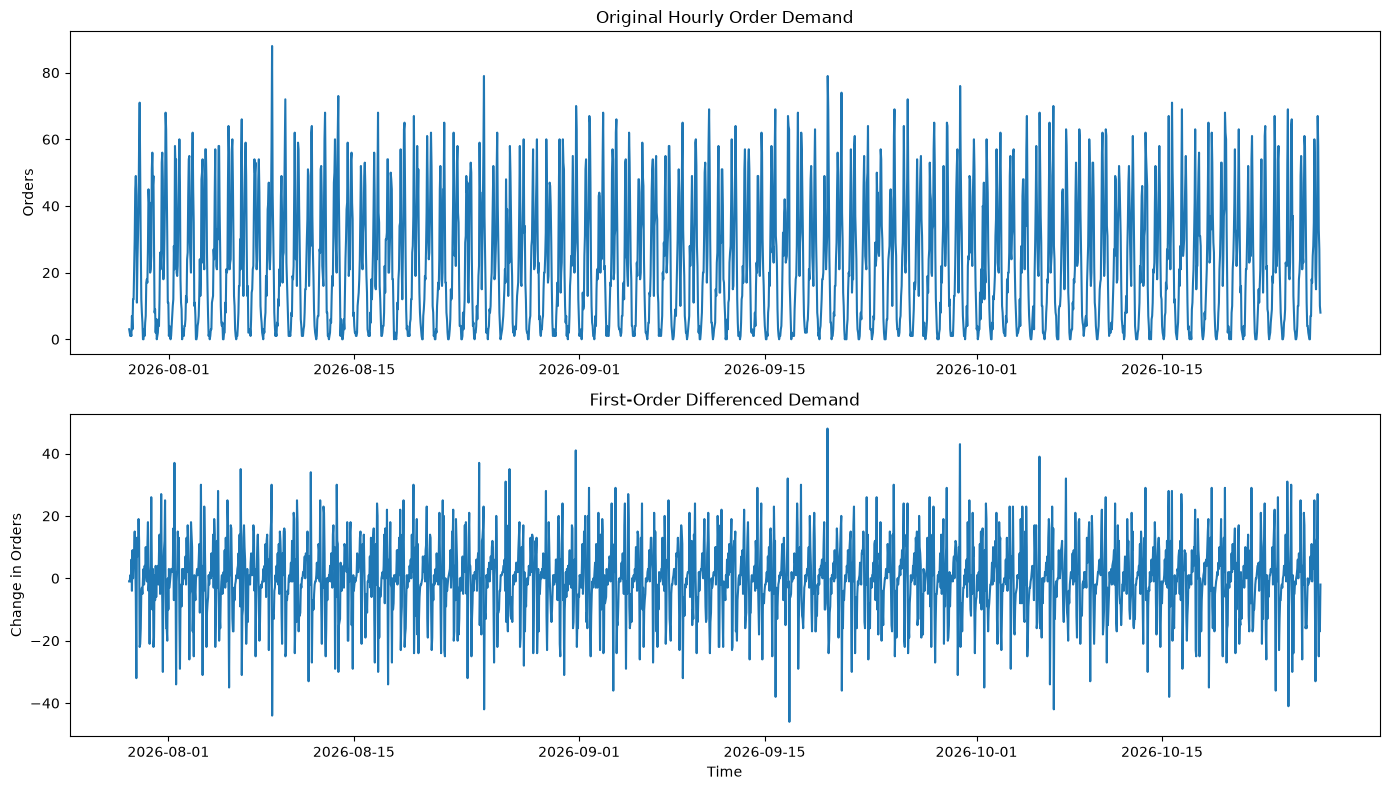

In [16]:

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(ts)
axes[0].set_title('Original Hourly Order Demand')
axes[0].set_ylabel('Orders')

axes[1].plot(ts_diff)
axes[1].set_title('First-Order Differenced Demand')
axes[1].set_ylabel('Change in Orders')
axes[1].set_xlabel('Time')

plt.tight_layout()
plt.show()


In [17]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Ensure hourly frequency and handle any missing values
ts = ts.asfreq('h').fillna(0)

# Forecast the final 24 hours
TEST_HOURS = 24

train = ts.iloc[:-TEST_HOURS]
test = ts.iloc[-TEST_HOURS:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Test period:", test.index.min(), "to", test.index.max())


Training observations: 2136
Testing observations: 24
Test period: 2026-10-26 00:00:00 to 2026-10-26 23:00:00


In [18]:

train_adf = adfuller(train)

if train_adf[1] <= 0.05:
    d = 0
    print("Training series appears stationary. Using d = 0")
else:
    diff_adf = adfuller(train.diff().dropna())

    if diff_adf[1] <= 0.05:
        d = 1
        print("First differencing helps. Using d = 1")
    else:
        d = 2
        print("First differencing was insufficient. Trying d = 2")

print("Selected d:", d)


Training series appears stationary. Using d = 0
Selected d: 0


/tmp/ipykernel_82151/961084241.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  train_adf = adfuller(train)


In [19]:

from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(
    train,
    order=(1, d, 1)
)

model_fit = model.fit()

print(model_fit.summary())


                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                 2136
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -8131.507
Date:                Thu, 29 Oct 2026   AIC                          16271.015
Time:                        10:18:38   BIC                          16293.682
Sample:                    07-29-2026   HQIC                         16279.310
                         - 10-25-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         23.1436      1.456     15.895      0.000      20.290      25.997
ar.L1          0.7081      0.022     31.787      0.000       0.664       0.752
ma.L1          0.3115      0.026     11.828      0.0

In [20]:

forecast_result = model_fit.get_forecast(steps=len(test))

forecast = forecast_result.predicted_mean
forecast.index = test.index

# Order counts cannot be negative
forecast = forecast.clip(lower=0)

forecast_df = pd.DataFrame({
    'actual_orders': test,
    'predicted_orders': forecast
})

forecast_df.head()


,actual_orders,predicted_orders
order_timestamp,,
2026-10-26 00:00:00,4,7.522660
2026-10-26 01:00:00,2,12.081786
2026-10-26 02:00:00,1,15.310286
2026-10-26 03:00:00,0,17.596516
2026-10-26 04:00:00,0,19.215487


In [21]:

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("ARIMA MAE:", round(mae, 2))
print("ARIMA RMSE:", round(rmse, 2))


ARIMA MAE: 14.21
ARIMA RMSE: 18.1


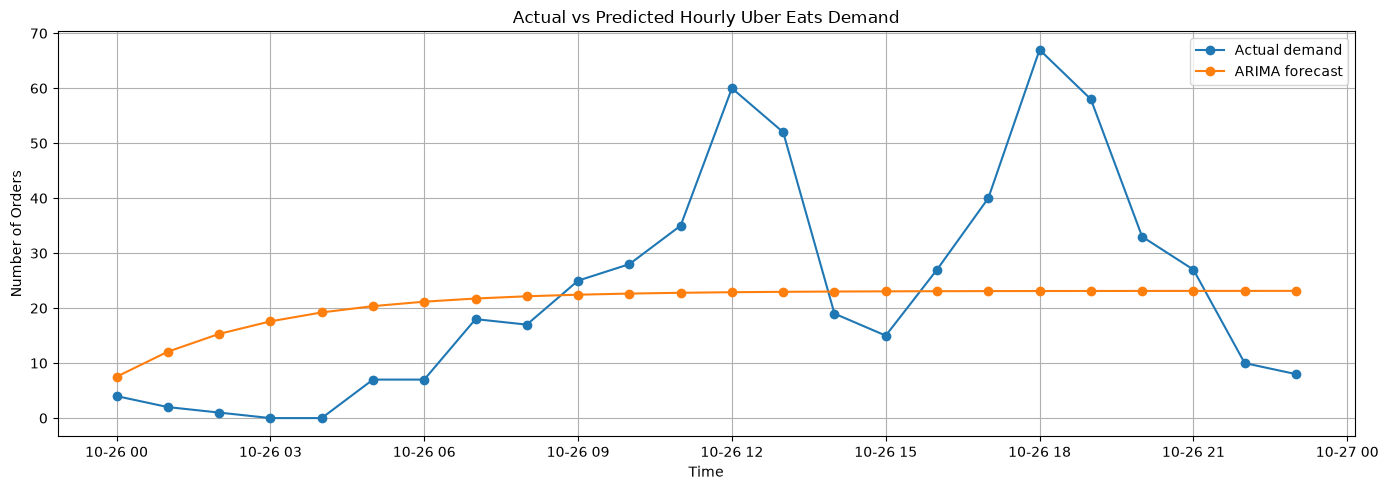

In [22]:

plt.figure(figsize=(14, 5))

plt.plot(test.index, test.values, marker='o', label='Actual demand')
plt.plot(forecast.index, forecast.values, marker='o', label='ARIMA forecast')

plt.title('Actual vs Predicted Hourly Uber Eats Demand')
plt.xlabel('Time')
plt.ylabel('Number of Orders')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [23]:

%pip install prophet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.9/56.9 kB 462.5 kB/s eta 0:00:00a 0:00:01
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 2.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 240.3 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 2.1 MB/s eta 0:00:00a 0:00:01m
Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl (229 kB)
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 3.0.0
    Uninstalling python-dateutil-3.0.0:
      Successfully uninstalled python-dateutil-3.0.0
Note: you may need to restart the kernel to use updated packages.


In [25]:

prophet_df = (
    ts.rename('y')
    .rename_axis('ds')
    .reset_index()
)

prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])
prophet_df = prophet_df.sort_values('ds').reset_index(drop=True)

prophet_df.head()


,ds,y
0,2026-07-29 00:00:00,3
1,2026-07-29 01:00:00,2
2,2026-07-29 02:00:00,1
3,2026-07-29 03:00:00,2
4,2026-07-29 04:00:00,1


In [26]:

# Create the Prophet model
prophet_model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False,
    seasonality_mode='additive'
)

# Add Indian public holidays where supported
prophet_model.add_country_holidays(country_name='India')


/home/ninelaps/uber-ml/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ninelaps/uber-ml/.venv/lib/python3.12/site-packages/prophet/make_holidays.py:48: UserWarning: Requested Holidays are available only from 2001 to 2035.
  return set(country_holidays(language="en_US", years=np.arange(1995, 2045)).values())


In [27]:

split_index = int(len(prophet_df) * 0.8)

train_df = prophet_df.iloc[:split_index].copy()
test_df = prophet_df.iloc[split_index:].copy()

print("Training period:", train_df['ds'].min(), "to", train_df['ds'].max())
print("Testing period:", test_df['ds'].min(), "to", test_df['ds'].max())
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))


Training period: 2026-07-29 00:00:00 to 2026-10-08 23:00:00
Testing period: 2026-10-09 00:00:00 to 2026-10-26 23:00:00
Training rows: 1728
Testing rows: 432


In [28]:

prophet_model.fit(train_df)

future = prophet_model.make_future_dataframe(
    periods=len(test_df),
    freq='h',
    include_history=True
)

prophet_forecast = prophet_model.predict(future)

# Keep predictions corresponding to the held-out test timestamps
predictions = (
    test_df[['ds', 'y']]
    .merge(
        prophet_forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']],
        on='ds',
        how='left'
    )
)

predictions.head()


10:23:23 - cmdstanpy - INFO - Chain [1] start processing
10:23:24 - cmdstanpy - INFO - Chain [1] done processing


,ds,y,yhat,yhat_lower,yhat_upper
0,2026-10-09 00:00:00,5,5.196984,-1.620376,12.384509
1,2026-10-09 01:00:00,4,4.334486,-2.400251,11.280959
2,2026-10-09 02:00:00,1,1.613589,-4.799445,8.219549
3,2026-10-09 03:00:00,3,-0.488661,-7.018054,6.094858
4,2026-10-09 04:00:00,4,1.148389,-5.591387,8.005888


In [29]:

mae_prophet = mean_absolute_error(
    predictions['y'],
    predictions['yhat']
)

rmse_prophet = np.sqrt(
    mean_squared_error(
        predictions['y'],
        predictions['yhat']
    )
)

print("Prophet MAE:", round(mae_prophet, 2))
print("Prophet RMSE:", round(rmse_prophet, 2))


Prophet MAE: 4.06
Prophet RMSE: 5.65


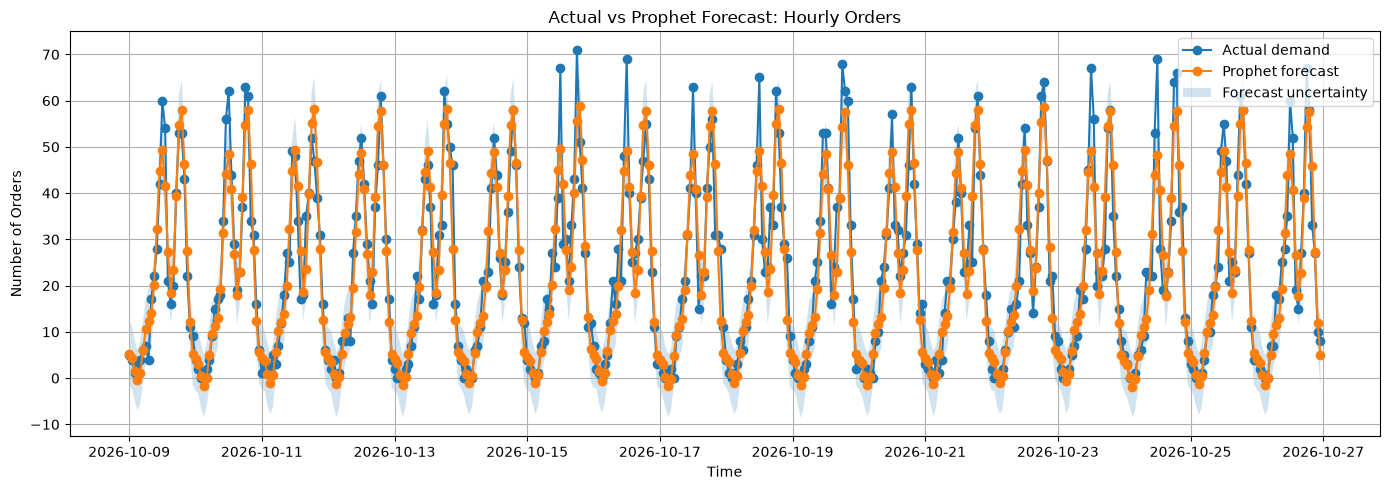

In [30]:

plt.figure(figsize=(14, 5))

plt.plot(
    predictions['ds'],
    predictions['y'],
    label='Actual demand',
    marker='o'
)

plt.plot(
    predictions['ds'],
    predictions['yhat'],
    label='Prophet forecast',
    marker='o'
)

plt.fill_between(
    predictions['ds'],
    predictions['yhat_lower'],
    predictions['yhat_upper'],
    alpha=0.2,
    label='Forecast uncertainty'
)

plt.title('Actual vs Prophet Forecast: Hourly Orders')
plt.xlabel('Time')
plt.ylabel('Number of Orders')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [31]:

comparison = pd.DataFrame({
    'Model': ['ARIMA', 'Prophet'],
    'MAE': [mae, mae_prophet],
    'RMSE': [rmse, rmse_prophet]
})

print(comparison)


     Model        MAE       RMSE
0    ARIMA  14.212187  18.097435
1  Prophet   4.060699   5.647459
